In [ ]:

# Week 3 - Supervised Machine Learning Models

## 1. Data Preparation

### Dataset Selection

I am using the Student Performance Factors dataset from Kaggle, which contains 6,607 student records.

For this assignment, I will convert Exam_Score into a binary classification target called Needs_Support.

Students scoring below 65 will be classified as needing academic support (1), while students scoring 65 or above will be classified as not needing support (0).

The goal is to compare KNN, Decision Tree, and Logistic Regression models for identifying students who may need additional support.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Find the attached dataset
csv_files = list(
    Path("/kaggle/input").rglob("StudentPerformanceFactors.csv")
)

if not csv_files:
    raise FileNotFoundError("Dataset not found. Attach it first.")

df = pd.read_csv(csv_files[0])

print("Dataset Shape:", df.shape)

display(df.head())

df.info()


Dataset Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje


### Initial Data Quality Check

I will check missing values and duplicate records to identify data quality issues before preprocessing.

Handling these issues helps produce a more reliable dataset for model training.


In [3]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())


Missing Values:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000



### Creating a Classification Target

The original Exam_Score is continuous, so it is more suitable for regression.

To perform classification, I will create a new binary target named Needs_Support, using 65 as a project-defined threshold.

I will examine the number of students in each class to determine whether the dataset is balanced.


Class Distribution:
Needs_Support
0    5155
1    1452
Name: count, dtype: int64

Class Percentages:
Needs_Support
0    78.023309
1    21.976691
Name: proportion, dtype: float64


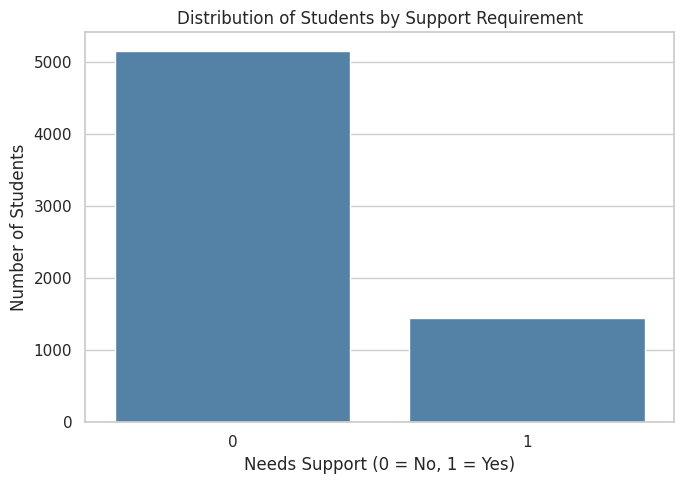

In [4]:

# Create binary classification target
df["Needs_Support"] = (df["Exam_Score"] < 65).astype(int)

# Count target classes
print("Class Distribution:")
print(df["Needs_Support"].value_counts().sort_index())

# Percentage distribution
print("\nClass Percentages:")
print(
    df["Needs_Support"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# Plot class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Needs_Support",
    order=[0, 1],
    color="steelblue"
)

plt.title("Distribution of Students by Support Requirement")
plt.xlabel("Needs Support (0 = No, 1 = Yes)")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()



### Class Distribution Observation

The dataset contains 5,155 students (78.02%) in Class 0 and 1,452 students (21.98%) in Class 1.

The dataset is imbalanced because most students belong to Class 0. Therefore, accuracy alone may not be enough to evaluate the models. I will also consider precision, recall, and F1-score, especially for students who need support.



### Data Cleaning and Feature Selection

I will remove duplicate records and retain missing values for handling during preprocessing.

I will also recreate two features from Week 2: Study_Attendance_Interaction and Study_Sleep_Ratio.

Exam_Score will be excluded from input features because Needs_Support was calculated directly from it. Including Exam_Score would cause target leakage.


In [5]:

# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

# Feature Engineering
df["Study_Attendance_Interaction"] = (
    df["Hours_Studied"] * df["Attendance"] / 100
)

df["Study_Sleep_Ratio"] = (
    df["Hours_Studied"] / df["Sleep_Hours"]
)

# Select input features and target
X = df.drop(columns=["Exam_Score", "Needs_Support"])
y = df["Needs_Support"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Features Shape: (6607, 21)
Target Shape: (6607,)

Target Distribution:
Needs_Support
0    5155
1    1452
Name: count, dtype: int64



### Train-Test Split

I will divide the dataset into 80% training data and 20% testing data.

I will use stratify=y to preserve the class proportions in both subsets, since the target classes are imbalanced.

random_state=42 ensures reproducible results.


In [6]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining Class Proportions:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Class Proportions:")
print(y_test.value_counts(normalize=True) * 100)


X_train: (5285, 21)
X_test: (1322, 21)
y_train: (5285,)
y_test: (1322,)

Training Class Proportions:
Needs_Support
0    78.032167
1    21.967833
Name: proportion, dtype: float64

Testing Class Proportions:
Needs_Support
0    77.987897
1    22.012103
Name: proportion, dtype: float64



### Data Preprocessing

I will use separate pipelines for numerical and categorical features.

For numerical columns, I will fill missing values using the median and then apply StandardScaler.

For categorical columns, I will fill missing values using the most frequent category and apply OneHotEncoder.

All preprocessing parameters will be learned only from the training data to prevent data leakage.


In [7]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify feature types
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical pipeline
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)


Preprocessing completed!
Training Shape: (5285, 42)
Testing Shape: (1322, 42)



### Preprocessing Verification

I will verify that the processed features contain no missing or infinite values and that the training and testing sets have the same number of features.

This ensures the datasets are suitable for model training.


In [8]:

print("Final Training Shape:", X_train_processed.shape)
print("Final Testing Shape:", X_test_processed.shape)

print("\nMissing Values in Training:",
      np.isnan(X_train_processed).sum())

print("Missing Values in Testing:",
      np.isnan(X_test_processed).sum())

print("\nAll Training Values Finite:",
      np.isfinite(X_train_processed).all())

print("All Testing Values Finite:",
      np.isfinite(X_test_processed).all())

assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_test_processed).all()

assert X_train_processed.shape[1] == X_test_processed.shape[1]

print("\nData is ready for model training!")


Final Training Shape: (5285, 42)
Final Testing Shape: (1322, 42)

Missing Values in Training: 0
Missing Values in Testing: 0

All Training Values Finite: True
All Testing Values Finite: True

Data is ready for model training!



## 2. K-Nearest Neighbors (KNN)

### Initial Model with K = 5

I will first train a KNN classifier using five neighbors.

I will reserve part of the training data for validation so that I can compare different K values without using the test set.

The final test set will remain untouched until model evaluation.


In [9]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

# Create a validation split from training data
X_fit_raw, X_val_raw, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Fit preprocessing only on the validation-training subset
tuning_preprocessor = clone(preprocessor)

X_fit = tuning_preprocessor.fit_transform(X_fit_raw)
X_val = tuning_preprocessor.transform(X_val_raw)

# Train initial KNN model
knn_5 = KNeighborsClassifier(n_neighbors=5)
knn_5.fit(X_fit, y_fit)

# Predict validation data
y_val_pred = knn_5.predict(X_val)

print("KNN Model with K = 5")
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Class 1 F1-score:", f1_score(y_val, y_val_pred))


KNN Model with K = 5
Validation Accuracy: 0.8864711447492905
Class 1 F1-score: 0.6954314720812182



### Finding the Best K Value

I will test odd K values from 1 to 15 and compare their validation accuracy.

A very small K can make the model sensitive to individual training examples, while a larger K produces smoother decision boundaries.

I will also record the F1-score for students needing support because the dataset has imbalanced classes.


In [10]:

k_values = list(range(1, 16, 2))

accuracies = []
f1_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_fit, y_fit)

    predictions = model.predict(X_val)

    accuracies.append(accuracy_score(y_val, predictions))
    f1_scores.append(f1_score(y_val, predictions, zero_division=0))

# Results table
knn_results = pd.DataFrame({
    "K": k_values,
    "Accuracy": accuracies,
    "Class_1_F1": f1_scores
})

display(knn_results.round(4))


,K,Accuracy,Class_1_F1
0,1,0.8666,0.6651
1,3,0.8798,0.6880
2,5,0.8865,0.6954
3,7,0.8988,0.7235
4,9,0.8950,0.7117
5,11,0.8988,0.7206
6,13,0.8931,0.7018
7,15,0.8950,0.7071



### K versus Accuracy Visualization

I will plot validation accuracy against different K values to observe how the number of neighbors affects model performance.

The graph will help me identify a suitable K value for the final KNN classifier.


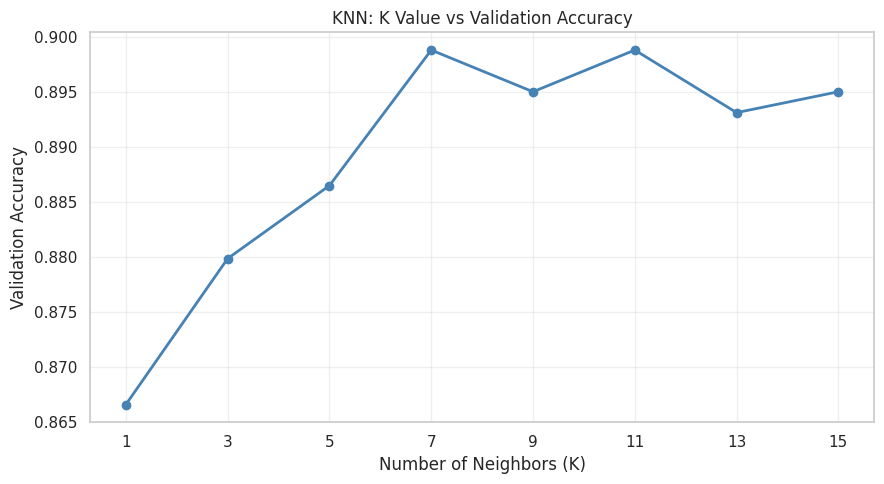

In [11]:

plt.figure(figsize=(9, 5))

plt.plot(
    knn_results["K"],
    knn_results["Accuracy"],
    marker="o",
    linewidth=2,
    color="steelblue"
)

plt.title("KNN: K Value vs Validation Accuracy")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Validation Accuracy")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### Selecting the Best KNN Model

I will select the K value with the highest validation accuracy. If multiple K values have the same accuracy, I will prefer the one with the higher F1-score for Class 1.

After selection, I will retrain the model on the complete training set. I will evaluate it on the test set later along with the other classifiers.


In [12]:

# Select best K using validation results
best_row = knn_results.sort_values(
    by=["Accuracy", "Class_1_F1", "K"],
    ascending=[False, False, True]
).iloc[0]

best_k = int(best_row["K"])

print("Best K:", best_k)
print("Best Validation Accuracy:", round(best_row["Accuracy"], 4))
print("Class 1 F1-score:", round(best_row["Class_1_F1"], 4))

# Train final KNN on the full training set
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_processed, y_train)

print("\nFinal KNN model trained successfully!")


Best K: 7
Best Validation Accuracy: 0.8988
Class 1 F1-score: 0.7235

Final KNN model trained successfully!



### KNN Results and Observations

I tested odd K values from 1 to 15.

K=7 and K=11 achieved the highest validation accuracy of approximately 89.88%. I selected K=7 because it had a slightly higher F1-score (0.7235) for students needing academic support.

Increasing K initially improved accuracy, but the performance fluctuated at larger values. This shows that selecting an appropriate K is important for model performance.



## 3. Decision Tree Classifier

### Initial Decision Tree Model

I will train a Decision Tree classifier to predict whether a student needs academic support.

Decision Trees learn decision rules from features and divide the data into groups to make predictions.

I will first train a model with max_depth=3 and evaluate its validation performance.


In [13]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

# Initial Decision Tree
tree_3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Train the model
tree_3.fit(X_fit, y_fit)

# Validation predictions
tree_predictions = tree_3.predict(X_val)

print("Decision Tree with max_depth=3")
print("Validation Accuracy:",
      accuracy_score(y_val, tree_predictions))

print("Class 1 F1-score:",
      f1_score(y_val, tree_predictions, zero_division=0))


Decision Tree with max_depth=3
Validation Accuracy: 0.8675496688741722
Class 1 F1-score: 0.6888888888888889



### Finding the Best Tree Depth

I will compare Decision Trees with maximum depths of 2, 3, 5, 10, and None.

I will record training accuracy, validation accuracy, and Class 1 F1-score.

Comparing training and validation results will help me identify possible overfitting when the tree becomes too deep.


In [14]:

depth_options = [2, 3, 5, 10, None]

tree_results = []

for i, depth in enumerate(depth_options):

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_fit, y_fit)

    train_pred = model.predict(X_fit)
    val_pred = model.predict(X_val)

    tree_results.append({
        "Depth": str(depth),
        "Train_Accuracy": accuracy_score(y_fit, train_pred),
        "Val_Accuracy": accuracy_score(y_val, val_pred),
        "Class_1_F1": f1_score(y_val, val_pred, zero_division=0),
        "Depth_Order": i
    })

tree_results_df = pd.DataFrame(tree_results)

display(
    tree_results_df.drop(columns="Depth_Order").round(4)
)


,Depth,Train_Accuracy,Val_Accuracy,Class_1_F1
0,2,0.8649,0.8723,0.6824
1,3,0.8654,0.8675,0.6889
2,5,0.8940,0.8751,0.6842
3,10,0.9839,0.8751,0.7080
4,None,1.0000,0.8742,0.7140



### Decision Tree Depth and Overfitting

I will plot training and validation accuracy for different tree depths.

If training accuracy continues to improve while validation accuracy becomes worse, this may indicate overfitting.

Overfitting means the model learns training examples too closely and may perform poorly on unseen data.


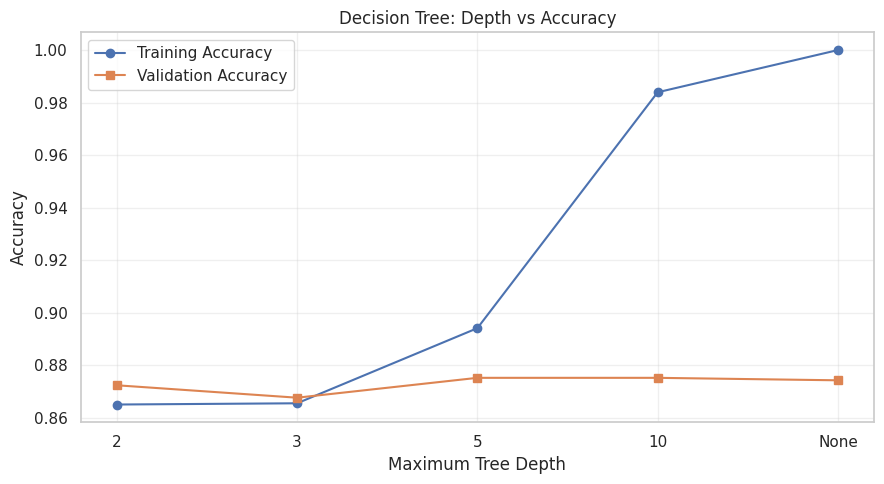

In [15]:

plt.figure(figsize=(9, 5))

plt.plot(
    tree_results_df["Depth"],
    tree_results_df["Train_Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    tree_results_df["Depth"],
    tree_results_df["Val_Accuracy"],
    marker="s",
    label="Validation Accuracy"
)

plt.title("Decision Tree: Depth vs Accuracy")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### Decision Tree Results and Observations

The graph shows that training accuracy increases as the tree becomes deeper, eventually reaching 100% when max_depth=None.

However, validation accuracy remains around 87%–88% and does not improve significantly with deeper trees.

This indicates overfitting. The deeper trees learn the training examples very closely but do not generalize better to unseen data.

A smaller tree, such as max_depth=5, provides a better balance between model complexity and performance.



### Selecting the Best Decision Tree

I will select the tree depth with the highest validation accuracy.

If multiple depths achieve the same accuracy, I will prefer the higher Class 1 F1-score and then the simpler tree.

After choosing the depth, I will retrain the model using the full training dataset.


In [16]:

# Select best model configuration
best_tree_row = tree_results_df.sort_values(
    by=["Val_Accuracy", "Class_1_F1", "Depth_Order"],
    ascending=[False, False, True]
).iloc[0]

best_depth = depth_options[int(best_tree_row["Depth_Order"])]

print("Best Tree Depth:", best_depth)
print("Best Validation Accuracy:",
      round(best_tree_row["Val_Accuracy"], 4))
print("Class 1 F1-score:",
      round(best_tree_row["Class_1_F1"], 4))

# Train final Decision Tree on all training data
tree_best = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=42
)

tree_best.fit(X_train_processed, y_train)

print("\nFinal Decision Tree trained successfully!")


Best Tree Depth: 10
Best Validation Accuracy: 0.8751
Class 1 F1-score: 0.708

Final Decision Tree trained successfully!



## 4. Logistic Regression

### Training the Logistic Regression Model

I will train a Logistic Regression classifier to predict whether students need academic support.

Logistic Regression estimates the probability of a student belonging to each class.

I will first evaluate the model on validation data and then train the final model using the complete training dataset.


In [17]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Train on validation-training subset
logistic_val = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_val.fit(X_fit, y_fit)

# Validation predictions
logistic_val_pred = logistic_val.predict(X_val)

print("Logistic Regression Results")

print("Validation Accuracy:",
      accuracy_score(y_val, logistic_val_pred))

print("Class 1 F1-score:",
      f1_score(y_val, logistic_val_pred, zero_division=0))

# Train final model on complete training data
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("\nFinal Logistic Regression trained successfully!")


Logistic Regression Results
Validation Accuracy: 0.988647114474929
Class 1 F1-score: 0.9739130434782609

Final Logistic Regression trained successfully!



### Predicting Class Probabilities

I will use predict_proba() to calculate the probability of each class for five test students.

Class 0 represents students who do not need academic support, while Class 1 represents students who need support.

These probabilities help explain the model's confidence in its predictions.


In [18]:

# Select first five test students
first_5_students = X_test_processed[:5]

# Predict probabilities
probabilities = logistic_model.predict_proba(first_5_students)

# Predict classes
predicted_classes = logistic_model.predict(first_5_students)

# Create results table
probability_results = pd.DataFrame({
    "Student": range(1, 6),
    "P(No Support)": probabilities[:, 0],
    "P(Needs Support)": probabilities[:, 1],
    "Predicted Class": predicted_classes
})

display(probability_results.round(4))


,Student,P(No Support),P(Needs Support),Predicted Class
0,1,0.9653,0.0347,0
1,2,0.9995,0.0005,0
2,3,1.0000,0.0000,0
3,4,0.9867,0.0133,0
4,5,0.0194,0.9806,1



### Logistic Regression Probability Observations

The model predicted that four of the first five test students do not need academic support, while one student needs support.

Student 5 had a 98.06% predicted probability of needing support and was classified as Class 1.

These results demonstrate how Logistic Regression provides class probabilities in addition to predictions.



### Logistic Regression Prediction Check

I will confirm that the model produces valid class predictions and that the predicted probabilities for each student sum to one.

The final comparison with KNN and Decision Tree will be performed separately using the test dataset.


In [19]:

# Verify predictions and probabilities
print("Predicted Classes:")
print(predicted_classes)

print("\nProbability Sums:")
print(probabilities.sum(axis=1))

assert np.allclose(probabilities.sum(axis=1), 1.0)
assert set(predicted_classes).issubset({0, 1})

print("\nLogistic Regression validation passed!")


Predicted Classes:
[0 0 0 0 1]

Probability Sums:
[1. 1. 1. 1. 1.]

Logistic Regression validation passed!



## 5. Model Evaluation and Comparison

I will evaluate KNN, Decision Tree, and Logistic Regression using the test dataset.

I will calculate accuracy, precision, recall, and F1-score for each model.

Since the dataset is imbalanced, I will focus on Class 1 (students needing support) when comparing precision, recall, and F1-score.


In [20]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Store trained models
models = {
    "KNN": knn_best,
    "Decision Tree": tree_best,
    "Logistic Regression": logistic_model
}

results = []
predictions = {}

# Evaluate all three models
for name, model in models.items():

    y_pred = model.predict(X_test_processed)

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

# Comparison table
results_df = pd.DataFrame(results)

print("MODEL COMPARISON")
display(results_df.round(4))


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1
0,KNN,0.8797,0.8474,0.5533,0.6694
1,Decision Tree,0.8699,0.7117,0.6873,0.6993
2,Logistic Regression,0.9826,0.9786,0.9416,0.9597



### Classification Reports

I will generate classification reports for all three models.

These reports show precision, recall, F1-score, and support for both classes.

This helps me understand how well each model identifies students who need academic support.


In [21]:

for name, y_pred in predictions.items():

    print("=" * 50)
    print(name.upper())
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Support", "Needs Support"],
        zero_division=0
    ))


KNN
               precision    recall  f1-score   support

   No Support       0.89      0.97      0.93      1031
Needs Support       0.85      0.55      0.67       291

     accuracy                           0.88      1322
    macro avg       0.87      0.76      0.80      1322
 weighted avg       0.88      0.88      0.87      1322

DECISION TREE
               precision    recall  f1-score   support

   No Support       0.91      0.92      0.92      1031
Needs Support       0.71      0.69      0.70       291

     accuracy                           0.87      1322
    macro avg       0.81      0.80      0.81      1322
 weighted avg       0.87      0.87      0.87      1322

LOGISTIC REGRESSION
               precision    recall  f1-score   support

   No Support       0.98      0.99      0.99      1031
Needs Support       0.98      0.94      0.96       291

     accuracy                           0.98      1322
    macro avg       0.98      0.97      0.97      1322
 weighted avg      


### Classification Report Observations

Logistic Regression achieved the strongest overall results, with approximately 98% accuracy and a Class 1 F1-score of 0.96.

KNN achieved 88% accuracy but had relatively low recall (0.55) for students needing support.

Decision Tree achieved 87% accuracy and improved Class 1 recall to 0.69.

Logistic Regression performed best at identifying students who need academic support while maintaining high precision.



### Confusion Matrix Analysis

I will use confusion matrices to examine correct and incorrect predictions made by each model.

In this problem, false negatives are particularly important because they represent students who need academic support but are incorrectly classified as not needing it.


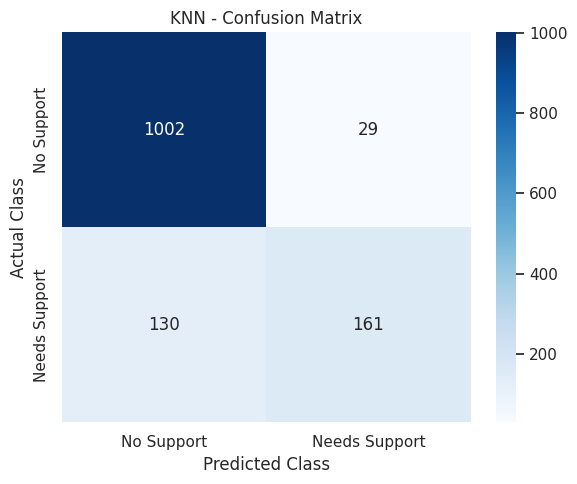

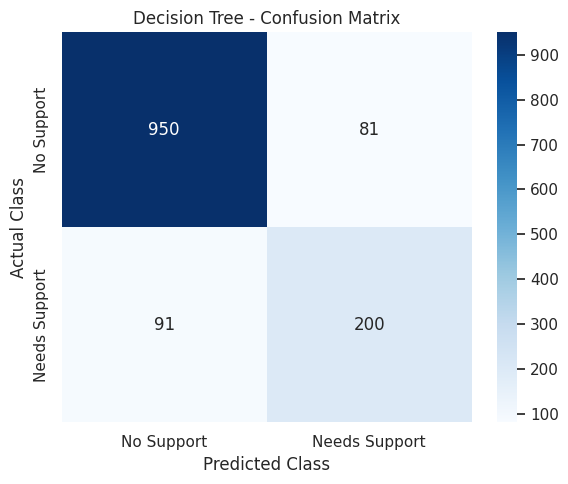

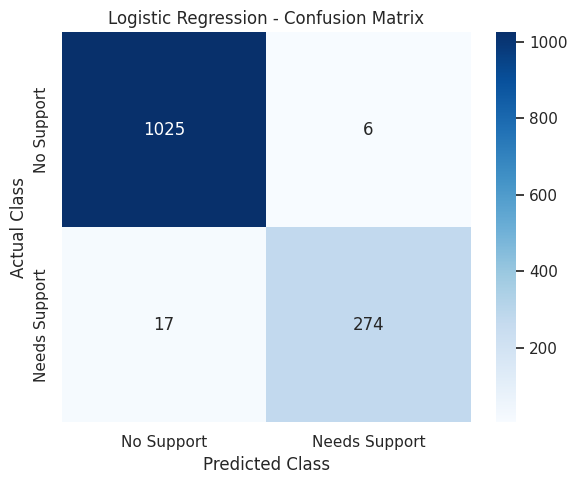

In [22]:

for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Support", "Needs Support"],
        yticklabels=["No Support", "Needs Support"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()
    plt.show()



### KNN Confusion Matrix Observations

The KNN model correctly identified 1,002 students who did not need support and 161 students who needed support.

However, it produced 29 false positives and 130 false negatives.

The model achieved approximately 88% accuracy, but its recall for students needing support was only 55%.

This means KNN missed nearly 45% of the students who actually needed support. Therefore, accuracy alone does not fully represent the model's effectiveness.



### Decision Tree Confusion Matrix Observations

The Decision Tree correctly classified 950 students who did not need support and 200 students who needed support.

However, it produced 81 false positives and 91 false negatives.

The model achieved approximately 87% accuracy and 69% recall for Class 1. Although it identified more students needing support than KNN, it still missed 91 students.



### Logistic Regression Confusion Matrix Observations

Logistic Regression correctly identified 1,025 students who did not need support and 274 students who needed support.

It produced only 6 false positives and 17 false negatives.

The model achieved approximately 98% accuracy and 94% recall for Class 1.

Compared with KNN and Decision Tree, Logistic Regression made significantly fewer classification errors and was more effective at identifying students needing academic support.



## 6. Model Comparison and Discussion

### Best Performing Model

Logistic Regression performed best on the test dataset, achieving 98.26% accuracy and a Class 1 F1-score of 95.97%.

KNN achieved 87.97% accuracy but missed 130 students needing support. Decision Tree achieved 86.99% accuracy and missed 91 students.

Logistic Regression missed only 17 students, making it the most suitable model among the three tested classifiers for this dataset.

This conclusion is based on performance on the held-out test set.



## 7. Bonus: Is Accuracy Alone Misleading?

The dataset is imbalanced, with approximately 78% of students in Class 0 and 22% in Class 1.

A model that always predicts Class 0 could achieve around 78% accuracy while failing to identify any students who need support.

KNN achieved nearly 88% accuracy, but its Class 1 F1-score was only 0.67 and recall was 0.55.

This demonstrates that accuracy alone can give a misleading impression of model performance.

For this problem, recall is particularly important because false negatives represent students who need support but are not identified.

F1-score is also useful because it considers both precision and recall.



### Error Analysis of the Best Model

I will examine the incorrectly classified students to understand where Logistic Regression makes mistakes.

I will compare their study hours, attendance, previous scores, and actual exam scores.

Actual exam scores will be used only for post-training error analysis, not as model input features.


In [23]:

# Predictions from best model
best_predictions = logistic_model.predict(X_test_processed)

# Identify incorrect predictions
error_mask = best_predictions != y_test.to_numpy()

# Get indices of incorrectly classified students
error_indices = y_test.index[error_mask]

# Examine incorrect records
error_analysis = X_test.loc[
    error_indices,
    ["Hours_Studied", "Attendance", "Previous_Scores"]
].copy()

error_analysis["Exam_Score"] = df.loc[
    error_indices, "Exam_Score"
]

error_analysis["Actual_Class"] = y_test.loc[
    error_indices
]

error_analysis["Predicted_Class"] = best_predictions[error_mask]

print("Total Incorrect Predictions:", len(error_analysis))

display(error_analysis.head(10))


Total Incorrect Predictions: 23


,Hours_Studied,Attendance,Previous_Scores,Exam_Score,Actual_Class,Predicted_Class
78,21,72,57,64,1,0
1849,23,71,50,64,1,0
751,12,68,75,64,1,0
1099,22,75,66,80,0,1
87,22,86,54,64,1,0
6577,14,73,57,64,1,0
4278,20,73,60,64,1,0
6276,25,66,71,64,1,0
6582,18,68,96,65,0,1
4198,2,98,64,65,0,1



### Error Analysis Observations

Logistic Regression made 23 incorrect predictions out of 1,322 test records, including 17 false negatives and 6 false positives.

Among the first 10 incorrectly classified students, nine had exam scores of 64 or 65, close to the classification threshold.

This suggests that the model sometimes struggles to distinguish students near the cutoff. One student with a score of 80 was also incorrectly classified as needing support.

Overall, Logistic Regression performed well, but its mistakes show that some students may still be misclassified.



### Distribution of Incorrect Predictions

I will examine the exam scores of all incorrectly classified students to identify whether errors are concentrated near the classification threshold of 65.


In [24]:

# Count incorrect predictions by exam score
print("Incorrect Predictions by Exam Score:")

print(
    error_analysis["Exam_Score"]
    .value_counts()
    .sort_index()
)

# Count mistakes around the threshold
near_threshold = error_analysis[
    error_analysis["Exam_Score"].isin([64, 65])
]

print("\nTotal Incorrect Predictions:", len(error_analysis))
print("Errors at Scores 64 or 65:", len(near_threshold))

print(
    "Percentage Near Threshold:",
    round(len(near_threshold) / len(error_analysis) * 100, 2),
    "%"
)


Incorrect Predictions by Exam Score:
Exam_Score
64    17
65     4
80     1
82     1
Name: count, dtype: int64

Total Incorrect Predictions: 23
Errors at Scores 64 or 65: 21
Percentage Near Threshold: 91.3 %



## 8. Conclusion

In this assignment, I trained and evaluated three supervised classification models using the Student Performance Factors dataset.

KNN achieved approximately 88% test accuracy, while Decision Tree achieved 87%. Logistic Regression performed best, achieving approximately 98.26% accuracy and a Class 1 F1-score of 0.96.

The dataset was imbalanced, so I also considered precision, recall, and F1-score instead of relying only on accuracy.

For this problem, recall is particularly important because failing to identify a student who needs academic support could prevent that student from receiving help.

The results show that Logistic Regression is the strongest of the three tested models for predicting the score-based support category.

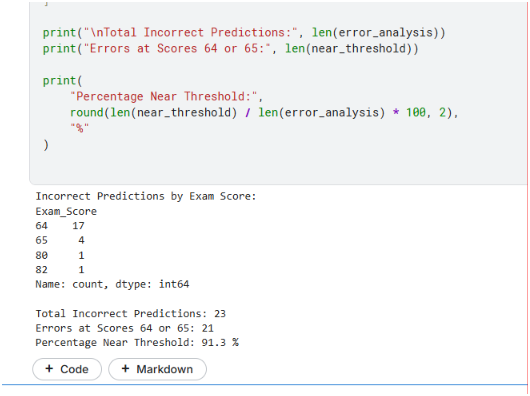